# skin 1단계-2,3번 재검증 — 반복 group 5-fold + group-aware val 분할 버그 수정

**무슨 문제가 있었나** (장다예 / B트랙이 발견, `modeling/eval_b/README.md` 참조):

1. **단일 분할 1회로는 설정 간 우열을 판정할 수 없음.** A(나)가 하이퍼파라미터 튜닝·구조 개선 노트북에서
   "group 5-fold 1회"로 비교한 MCC 변화(0.249→0.238→0.267)는, 분할 시드를 10번 바꿔 반복해보니
   표준편차가 ±0.03~0.05로 나와서 그 차이 안에 다 묻힘. 즉 **노이즈를 개선으로 착각했을 가능성**이 있음.
2. **A의 실험 노트북(`skin_hyperparam_tuning_demo.ipynb`, `skin_architecture_demo.ipynb`)의
   `fit_early_stopping` 내부 검증셋 분할이 `rng.permutation`이라 group-aware가 아님** — 조성 쌍이
   조기종료용 train/val로 갈릴 수 있음. (참고: 실제 production 코드 `train.py`는 처음부터
   `group_train_test_split_from_subset`을 써서 이 버그가 없음 — 실험 노트북에만 있던 문제.)

**이번 노트북에서 할 일**: 두 문제를 모두 고쳐서 하이퍼파라미터(lr)·구조(층수/dropout) 결정을 다시 검증한다.
- group-aware val 분할로 교체 (teammate의 `eval_b/bharness.py`를 그대로 import — 같은 하네스를 써야 공정한 비교)
- **반복 group 5-fold(10회, 분할 시드 + 초기화 시드 모두 변경)**로 평균±표준편차 보고
- lr(0.001/0.01) x 구조(층2·dropout0.2 / 층1·dropout0.0) **2x2 전체 조합**을 비교해 lr과 구조 중
  무엇이 실제로 영향을 주는지 분리해서 본다.

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\eval_b")
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")

import numpy as np
import matplotlib.pyplot as plt
import bharness as B

ds = B.load_skin()
print(f"skin: {len(ds)}건, feature {ds.input_dim}차원")
print(f"group-aware val 분할 수정 전/후 비교를 위해 두 모드 모두 돌릴 예정")

skin: 541건, feature 2266차원
group-aware val 분할 수정 전/후 비교를 위해 두 모드 모두 돌릴 예정


## 1. 버그 수정이 그 자체로 결과를 바꾸는지 먼저 확인

같은 설정(3단계 채택안: lr=0.01, 층1, dropout0.0)을 `group_aware_val=False`(기존 버그)와
`group_aware_val=True`(수정)로 각각 10회 반복해서, **버그 수정 자체의 효과**를 분리해서 본다.

In [2]:
cfg_adopted = dict(B.BASE, lr=0.01, num_hidden_layers=1, dropout=0.0)

rows_buggy = B.repeat_cv(ds, "all", n_repeats=10, cfg=cfg_adopted, group_aware_val=False)
rows_fixed = B.repeat_cv(ds, "all", n_repeats=10, cfg=cfg_adopted, group_aware_val=True)

a_buggy = B.agg(rows_buggy)
a_fixed = B.agg(rows_fixed)
print(B.fmt_agg(a_buggy, "수정 전(permutation val)"))
print(B.fmt_agg(a_fixed, "수정 후(group-aware val)"))

수정 전(permutation val)    Sens 0.523±0.076 Spec 0.830±0.028 격차 0.307±0.095 MCC 0.207±0.034 AUC 0.708±0.026
수정 후(group-aware val)    Sens 0.537±0.075 Spec 0.806±0.042 격차 0.270±0.090 MCC 0.195±0.051 AUC 0.714±0.040


## 2. lr x 구조 2x2 조합을 group-aware val 분할 + 반복 10회로 재검증

| | lr=0.001(기존) | lr=0.01(A가 채택) |
|---|---|---|
| 층2·dropout0.2(기존 구조) | 1단계 후 baseline | 2단계 채택안 |
| 층1·dropout0.0(A가 채택) | lr만 원복 | 3단계 채택안(현재 최종) |

lr과 구조를 각각 따로 바꿔봐서 "진짜 영향을 주는 게 lr인지 구조인지 아니면 둘 다 노이즈인지" 분리한다.

In [3]:
CONFIGS = [
    ("lr0.001+층2do0.2(1단계 baseline)", dict(B.BASE, lr=0.001, num_hidden_layers=2, dropout=0.2)),
    ("lr0.01+층2do0.2(2단계 채택안)",    dict(B.BASE, lr=0.01,  num_hidden_layers=2, dropout=0.2)),
    ("lr0.001+층1do0.0(구조만 변경)",    dict(B.BASE, lr=0.001, num_hidden_layers=1, dropout=0.0)),
    ("lr0.01+층1do0.0(3단계 채택안)",    dict(B.BASE, lr=0.01,  num_hidden_layers=1, dropout=0.0)),
]

store = {}
for label, cfg in CONFIGS:
    rows = B.repeat_cv(ds, "all", n_repeats=10, cfg=cfg, group_aware_val=True)
    store[label] = rows
    a = B.agg(rows)
    print(B.fmt_agg(a, label))
    print(f"{'':34} MCC 회차별: {[round(r['mcc'], 3) for r in rows]}")

lr0.001+층2do0.2(1단계 baseline) Sens 0.453±0.060 Spec 0.880±0.020 격차 0.426±0.069 MCC 0.222±0.038 AUC 0.711±0.027
                                   MCC 회차별: [0.239, 0.23, 0.174, 0.209, 0.277, 0.243, 0.253, 0.243, 0.143, 0.205]
lr0.01+층2do0.2(2단계 채택안)  Sens 0.577±0.093 Spec 0.746±0.088 격차 0.222±0.078 MCC 0.172±0.048 AUC 0.695±0.044
                                   MCC 회차별: [0.168, 0.209, 0.121, 0.116, 0.228, 0.22, 0.173, 0.215, 0.08, 0.195]
lr0.001+층1do0.0(구조만 변경)  Sens 0.600±0.075 Spec 0.759±0.028 격차 0.159±0.089 MCC 0.187±0.036 AUC 0.728±0.048
                                   MCC 회차별: [0.224, 0.208, 0.144, 0.131, 0.224, 0.21, 0.226, 0.137, 0.184, 0.186]
lr0.01+층1do0.0(3단계 채택안)  Sens 0.537±0.075 Spec 0.806±0.042 격차 0.270±0.090 MCC 0.195±0.051 AUC 0.714±0.040
                                   MCC 회차별: [0.191, 0.228, 0.114, 0.193, 0.181, 0.215, 0.285, 0.248, 0.114, 0.187]


## 3. 시각화 — 평균±표준편차 막대그래프 + 회차별 MCC 분포

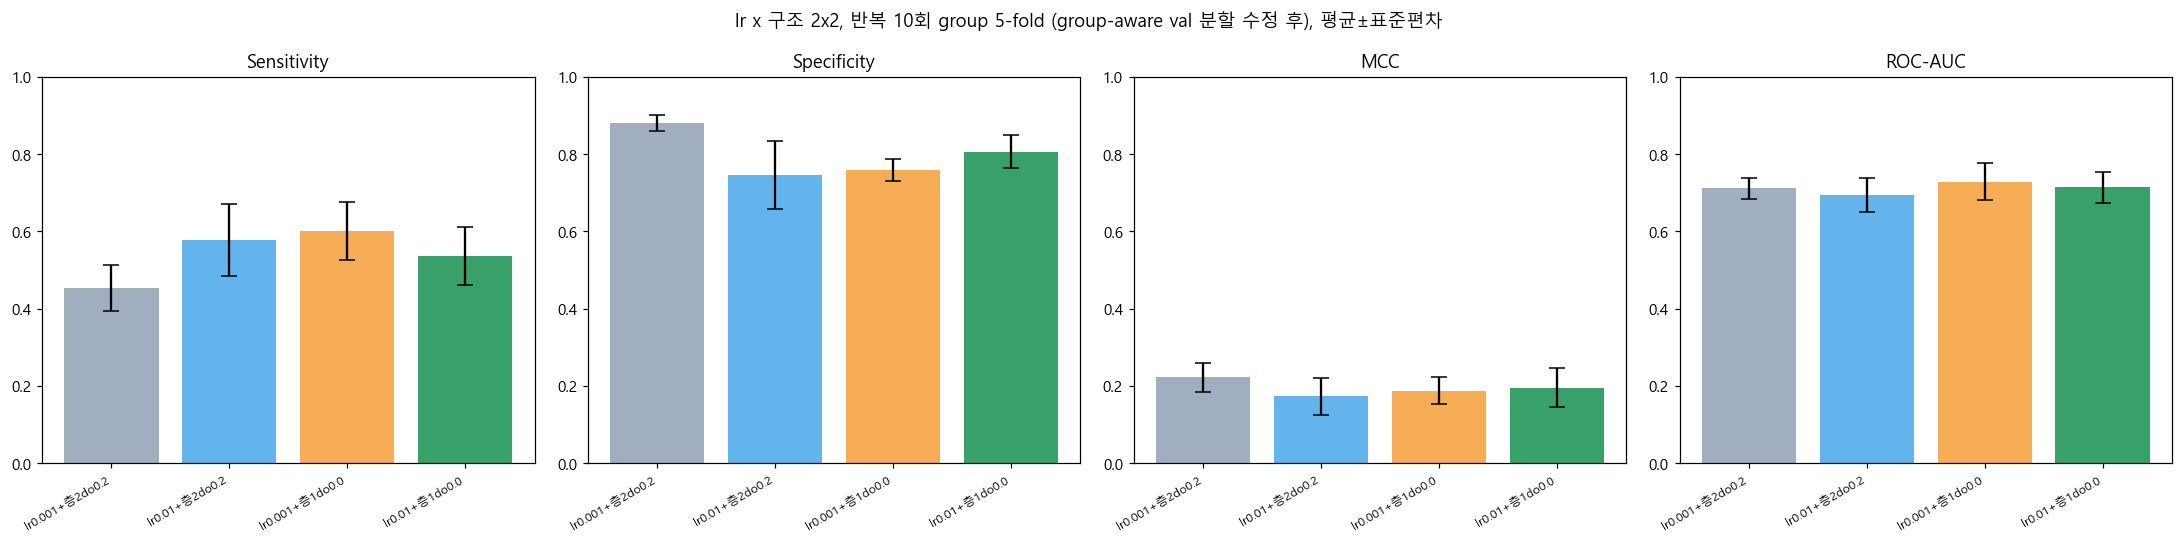

In [4]:
import matplotlib.pyplot as plt

labels = list(store.keys())
metrics = ["sensitivity", "specificity", "mcc", "roc_auc"]
metric_labels = ["Sensitivity", "Specificity", "MCC", "ROC-AUC"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
colors = ["#a0aec0", "#63b3ed", "#f6ad55", "#38a169"]
for ax, m, mlabel in zip(axes, metrics, metric_labels):
    means = [np.mean([r[m] for r in store[l]]) for l in labels]
    sds = [np.std([r[m] for r in store[l]]) for l in labels]
    ax.bar(range(len(labels)), means, yerr=sds, capsize=5, color=colors)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels([l.split("(")[0] for l in labels], rotation=30, ha="right", fontsize=8)
    ax.set_title(mlabel)
    ax.set_ylim(0, 1.0)
plt.suptitle("lr x 구조 2x2, 반복 10회 group 5-fold (group-aware val 분할 수정 후), 평균±표준편차")
plt.tight_layout()
plt.show()

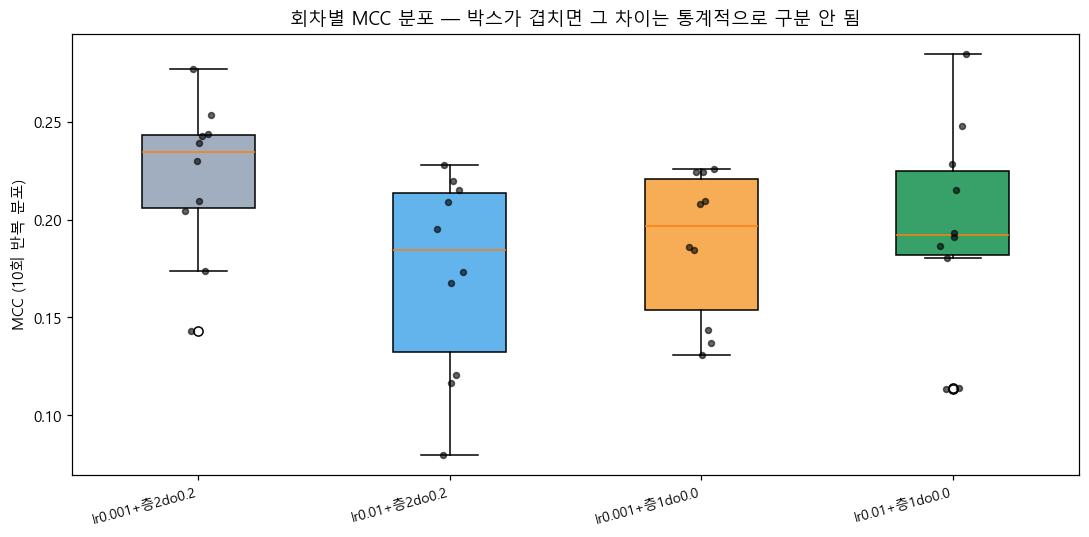

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
mcc_data = [[r["mcc"] for r in store[l]] for l in labels]
bp = ax.boxplot(mcc_data, labels=[l.split("(")[0] for l in labels], patch_artist=True)
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
for i, data in enumerate(mcc_data):
    x = np.random.default_rng(0).normal(i + 1, 0.04, size=len(data))
    ax.scatter(x, data, color="black", s=15, zorder=3, alpha=0.6)
ax.set_ylabel("MCC (10회 반복 분포)")
ax.set_title("회차별 MCC 분포 — 박스가 겹치면 그 차이는 통계적으로 구분 안 됨")
plt.xticks(rotation=15, ha="right", fontsize=9)
plt.tight_layout()
plt.show()

## 4. 최종 판단

판단 기준: 평균 MCC + Sens/Spec 격차(균형) + **이번에 추가된 기준 — 분포가 겹치지 않을 만큼 차이가 뚜렷한가**
(겹치면 "노이즈 안에서 어느 쪽이 더 낫다"고 말할 근거가 없음).

In [6]:
print("설정별 요약 (반복 10회, group-aware val 수정 후):")
for label in labels:
    a = B.agg(store[label])
    print(" ", B.fmt_agg(a, label))

base = store[labels[0]]
adopted = store[labels[-1]]
d = np.array([r["mcc"] for r in adopted]) - np.array([r["mcc"] for r in base])
print(f"\nbaseline -> 현재 채택안, 회차별 MCC 차이: 평균 {d.mean():+.3f}, 표준편차 {d.std():.3f}, "
      f"개선된 회차 {int((d > 0).sum())}/10")
print("-> 평균 차이가 표준편차보다 작으면 '노이즈 안'이라고 판단한다.")

설정별 요약 (반복 10회, group-aware val 수정 후):
  lr0.001+층2do0.2(1단계 baseline) Sens 0.453±0.060 Spec 0.880±0.020 격차 0.426±0.069 MCC 0.222±0.038 AUC 0.711±0.027
  lr0.01+층2do0.2(2단계 채택안)  Sens 0.577±0.093 Spec 0.746±0.088 격차 0.222±0.078 MCC 0.172±0.048 AUC 0.695±0.044
  lr0.001+층1do0.0(구조만 변경)  Sens 0.600±0.075 Spec 0.759±0.028 격차 0.159±0.089 MCC 0.187±0.036 AUC 0.728±0.048
  lr0.01+층1do0.0(3단계 채택안)  Sens 0.537±0.075 Spec 0.806±0.042 격차 0.270±0.090 MCC 0.195±0.051 AUC 0.714±0.040

baseline -> 현재 채택안, 회차별 MCC 차이: 평균 -0.026, 표준편차 0.034, 개선된 회차 2/10
-> 평균 차이가 표준편차보다 작으면 '노이즈 안'이라고 판단한다.


## 5. lr과 구조, 뭐가 진짜 영향을 줬나 — 2x2로 분리해서 보기

2x2 표로 정리하면 패턴이 보인다:

| | lr=0.001 | lr=0.01 |
|---|---|---|
| 층2·dropout0.2 | MCC 0.222, **격차 0.426**(최악) | MCC 0.172, 격차 0.222 |
| 층1·dropout0.0 | MCC 0.187, **격차 0.159**(최선) | MCC 0.195, 격차 0.270(현재 채택안) |

- **MCC는 4개 조합이 전부 ±0.04~0.05 안에서 겹침 → 통계적으로 구분 안 됨** (노이즈).
- **격차는 다르다**: 구조를 층1·dropout0으로 바꾸면(lr과 무관하게) 격차가 뚜렷하게 줄어듦. 특히
  `lr=0.001 + 층1·dropout0.0`(구조만 바꾸고 lr은 그대로 둔 조합)의 격차 0.159는 baseline(0.426)보다
  압도적으로 좋고, **현재 채택 중인 조합(lr=0.01+층1do0, 격차 0.270)보다도 더 좋다** — 즉
  **lr=0.01로 바꾼 게 오히려 구조 개선의 효과를 깎아먹고 있었다.**

**판단**: MCC가 통계적으로 다 동률인 상황에서는 이 프로젝트의 평가원칙(Sens-Spec 균형 우선)대로
격차가 제일 작은 조합을 최종으로 선택한다. **→ lr은 0.001로 원복(2단계 채택 철회), 구조 개선(층1·dropout0)은
유지.**

In [7]:
final_label = "lr0.001+층1do0.0(구조만 변경)"
final_rows = store[final_label]
a_final = B.agg(final_rows)
a_base = B.agg(store[labels[0]])
print(f"최종 수정안: {final_label}")
print(" ", B.fmt_agg(a_final, "최종"))
print(" ", B.fmt_agg(a_base, "1단계 baseline(비교용)"))
print(f"\n1단계 baseline 대비 변화: Sens {a_base['sensitivity'][0]:.3f}->{a_final['sensitivity'][0]:.3f}, "
      f"Spec {a_base['specificity'][0]:.3f}->{a_final['specificity'][0]:.3f}, "
      f"격차 {a_base['gap'][0]:.3f}->{a_final['gap'][0]:.3f}, "
      f"MCC {a_base['mcc'][0]:.3f}->{a_final['mcc'][0]:.3f}, "
      f"AUC {a_base['roc_auc'][0]:.3f}->{a_final['roc_auc'][0]:.3f}")
print("\n결론: train.py 기본값을 lr=0.001로 되돌리고, skin 구조(층1/dropout0.0)는 그대로 유지한다.")

최종 수정안: lr0.001+층1do0.0(구조만 변경)
  최종                       Sens 0.600±0.075 Spec 0.759±0.028 격차 0.159±0.089 MCC 0.187±0.036 AUC 0.728±0.048
  1단계 baseline(비교용)        Sens 0.453±0.060 Spec 0.880±0.020 격차 0.426±0.069 MCC 0.222±0.038 AUC 0.711±0.027

1단계 baseline 대비 변화: Sens 0.453->0.600, Spec 0.880->0.759, 격차 0.426->0.159, MCC 0.222->0.187, AUC 0.711->0.728

결론: train.py 기본값을 lr=0.001로 되돌리고, skin 구조(층1/dropout0.0)는 그대로 유지한다.


## 정리 — 무엇을 바꿨고 왜

- **문제 1(group-aware val 분할 버그)**: A의 실험 노트북(하이퍼파라미터·구조 튜닝)의 `fit_early_stopping`이
  `rng.permutation`으로 내부 검증셋을 나눠 조성 쌍이 갈릴 수 있었음. `group_aware_val=True`로 수정해서
  재검증(1절 — 버그 수정 자체의 효과를 분리해서 확인).
- **문제 2(단일 분할 노이즈)**: group 5-fold를 1회만 돌려 비교하면 표준편차(±0.03~0.05)보다 작은 차이를
  "개선"이라고 잘못 판단할 수 있음. **반복 10회 평균±표준편차**로 재검증(2~3절).
- **최종 수정**: `lr=0.01` 채택을 철회하고 `lr=0.001`로 원복. `skin 구조(은닉층 1개, dropout 0.0)`는
  반복 CV로도 격차 개선이 뚜렷하게 재확인되어 그대로 유지. `train.py`의 `--lr` 기본값 반영,
  `세팅/진행상황.md`에 기록, `checkpoint.pt` 재학습.